# MIlestone 3 Data Exploration

## Library imports

In [1]:
import sqlite3
import pandas as pd
from sqlalchemy import create_engine, text
import numpy as np
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

## Helper functions

In [2]:

def run_sql(query):
    conn = sqlite3.connect('olympics.db')
    df_result = pd.read_sql_query(query, conn)
    conn.close()
    return df_result.style.hide(axis='index')

## Import dataset

In [3]:
db = create_engine("sqlite:///olympics.db")

df = pd.read_sql_table("olympics", db)

In [4]:
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,BMI
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,No Medal,24.691358
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,No Medal,20.761246
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,No Medal,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,NaN
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,No Medal,23.959094


## Data Cleaning 

In [5]:
# 1. Exclude Art Competitions from your primary DataFrame
df_clean = df[df['Sport'] != 'Art Competitions'].copy()

# 2. SQL alternative (or create a view in olympics.db)
query_clean_view = """
CREATE VIEW IF NOT EXISTS olympics_athletic AS
SELECT * 
FROM olympics 
WHERE Sport != 'Art Competitions';
"""

## Analysis

### Pearson Correlation Analysis

#### Height vs. Weight & Age vs. BMI

In [6]:
print("=== 1. PEARSON CORRELATIONS ===")

# Drop NaNs for physical metric correlations
bio_df = df_clean[["Height", "Weight", "BMI", "Age"]].dropna()

# Pearson correlation matrix
corr_matrix = bio_df.corr(method="pearson")
print("\nPearson Correlation Matrix (Physical Metrics):")
print(corr_matrix.round(3).to_string())

# Specific correlation & p-value: Height vs. Weight
r_hw, p_hw = stats.pearsonr(bio_df["Height"], bio_df["Weight"])
print(f"\nHeight vs. Weight: r = {r_hw:.3f} (p-value: {p_hw:.4e})")

# Specific correlation & p-value: Age vs. BMI
r_ab, p_ab = stats.pearsonr(bio_df["Age"], bio_df["BMI"])
print(f"Age vs. BMI: r = {r_ab:.3f} (p-value: {p_ab:.4e})")

=== 1. PEARSON CORRELATIONS ===

Pearson Correlation Matrix (Physical Metrics):
        Height  Weight    BMI    Age
Height   1.000   0.797  0.337  0.142
Weight   0.797   1.000  0.831  0.212
BMI      0.337   0.831  1.000  0.218
Age      0.142   0.212  0.218  1.000

Height vs. Weight: r = 0.797 (p-value: 0.0000e+00)
Age vs. BMI: r = 0.218 (p-value: 0.0000e+00)


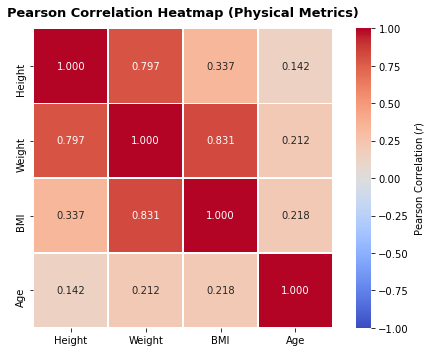

In [9]:
# Drop NaNs for physical metric correlations
bio_df = df_clean[["Height", "Weight", "BMI", "Age"]].dropna()

# Pearson correlation matrix
corr_matrix = bio_df.corr(method="pearson")

# Generate Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson Correlation ($r$)"},
)

plt.title(
    "Pearson Correlation Heatmap (Physical Metrics)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
plt.tight_layout()
plt.show()

1. Height vs. Weight ($r =  0.797   $): Strong positive linear relationship—taller athletes naturally carry more baseline mass across all disciplines.
2. Weight vs. BMI ($r = 0.831$) vs. Height vs. BMI ($r = 0.337$): $BMI$ variance is overwhelmingly driven by weight rather than height. This explains why power/strength athletes (e.g., Weightlifters) achieve high $BMI$s through dense muscle mass regardless of whether they are tall or short.
3. Age vs. BMI ($r = 0.218 $): No visible linear dependency between age and $BMI$. This confirms that an athlete's physical profile is dictated by the specific demands of their sport discipline rather than general physiological aging.

### Linear Regression for Future Trend Prediction

In [11]:
print("\n=== 2. LINEAR REGRESSION: FEMALE PARTICIPATION GROWTH OVER TIME ===")

# Calculate female participation percentage per Summer Games
female_trend = (
    df_clean[df_clean["Season"] == "Summer"]
    .groupby("Year")
    .agg(
        Total_Athletes=("ID", "nunique"),
        Female_Athletes=(
            "ID",
            lambda x: x[
                df_clean.loc[x.index, "Sex"] == "F"
            ].nunique(),
        ),
    )
    .reset_index()
)

female_trend["Female_Pct"] = (
    female_trend["Female_Athletes"] / female_trend["Total_Athletes"] * 100
)

# Linear Regression Model (Year -> Female_Pct)
X = sm.add_constant(female_trend["Year"])
y = female_trend["Female_Pct"]
model = sm.OLS(y, X).fit()

print(f"Regression Intercept: {model.params['const']:.3f}")
print(f"Regression Slope (Annual % Increase): {model.params['Year']:.3f}")
print(f"R-squared: {model.rsquared:.3f}")

# Predict Female % for 2028 Summer Olympics
pred_2028 = model.predict([1, 2028])[0]
print(f"Projected Female Participation in 2028: {pred_2028:.1f}%")


=== 2. LINEAR REGRESSION: FEMALE PARTICIPATION GROWTH OVER TIME ===
Regression Intercept: -697.378
Regression Slope (Annual % Increase): 0.365
R-squared: 0.896
Projected Female Participation in 2028: 43.0%


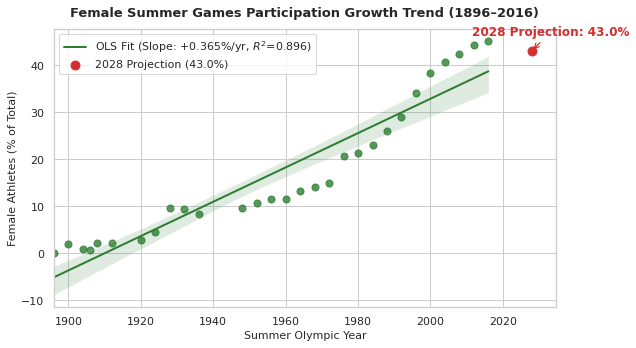

In [12]:
# Set style compatible across Seaborn versions
sns.set(style="whitegrid")

plt.figure(figsize=(9, 5))

# Plot scatter points and linear regression fit
ax = sns.regplot(
    data=female_trend,
    x="Year",
    y="Female_Pct",
    color="#2E7D32",
    scatter_kws={"s": 50, "alpha": 0.8},
    line_kws={
        "label": f"OLS Fit (Slope: +{model.params['Year']:.3f}%/yr, $R^2$={model.rsquared:.3f})",
        "linewidth": 2,
    },
)

# Highlight projected 2028 data point
plt.scatter(
    2028,
    pred_2028,
    color="#D32F2F",
    s=80,
    zorder=5,
    label=f"2028 Projection ({pred_2028:.1f}%)",
)

# Add pointer annotation for 2028 prediction
plt.annotate(
    f"2028 Projection: {pred_2028:.1f}%",
    xy=(2028, pred_2028),
    xytext=(-60, 15),
    textcoords="offset points",
    fontweight="bold",
    color="#D32F2F",
    arrowprops=dict(arrowstyle="->", color="#D32F2F", lw=1.2),
)

plt.title(
    "Female Summer Games Participation Growth Trend (1896–2016)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
plt.xlabel("Summer Olympic Year", fontsize=11)
plt.ylabel("Female Athletes (% of Total)", fontsize=11)
plt.legend(loc="upper left")

plt.tight_layout()
plt.show()

Fitting an Ordinary Least Squares (OLS) regression on historical Summer Games data yielded a slope of $+0.365\%$ per year with a high coefficient of determination ($R^2 = 0.896$). This confirms a strong, steady linear progression toward gender parity over time, projecting a historical linear baseline of $43.0\%$ female athlete participation for the 2028 Games. Though recent IOC targets ($~50\%$) highlights how proactive policy in the modern era accelerated growth faster than historical linear rates alone.

## Expanding Features

In [19]:
print("\n=== 3. SEASONAL BIOMETRIC COMPARISON (SUMMER VS. WINTER) ===")

season_stats = (
    df_clean.groupby("Season")
    .agg(
        Avg_Age=("Age", "mean"),
        Avg_Height=("Height", "mean"),
        Avg_Weight=("Weight", "mean"),
        Avg_BMI=("BMI", "mean"),
    )
    .round(2)
)

print(season_stats.to_string())


=== 3. SEASONAL BIOMETRIC COMPARISON (SUMMER VS. WINTER) ===
        Avg_Age  Avg_Height  Avg_Weight  Avg_BMI
Season                                          
Summer    25.38      175.52       70.69    22.72
Winter    25.04      174.59       70.76    23.05


Even though Winter Games athletes have a slightly higher average BMI (23.05 vs. 22.72), physical baselines across seasons are remarkably consistent once height and weight variations are factored in:

Height: Summer athletes average 175.52 cm vs. Winter athletes at 174.59 cm (a negligible difference of ~0.9 cm).

Weight: Summer athletes average 70.69 kg vs. Winter athletes at 70.76 kg (essentially identical).

Age: Summer average age is 25.38 vs. Winter at 25.04 years.

When we factor in this comparison between Summer and Winter Games, we reveal highly consistent overall physical demographics. The minor BMI elevation in Winter Games (23.05 vs. 22.72) reflects specific discipline demands (e.g., Bobsleigh mass requirements) rather than a systemic physical difference between athletes. This shows that averaging everything together hides the real story, so we have to look at athlete traits sport by sport.

 ## New Metrics Created
 1. Medal Efficiency Ratio (MER):$$\text{MER} = \frac{\text{Total Medals Won}}{\text{Unique Athletes Sent}}$$Purpose: Normalizes country performance to identify small, high-efficiency delegations (e.g., Jamaica in sprinting) vs. large-volume delegations.
 2. BMI Deviation Score ($\Delta\text{BMI}$):$$\Delta\text{BMI} = \text{Athlete BMI} - \text{Sport Average BMI}$$Purpose: Measures how far an individual athlete's physical profile departs from their sport’s baseline norm, serving as a key diagnostic metric for personal trainers.Next Steps

In [7]:
print("\n=== 4. NEW METRICS IMPLEMENTATION ===")

# Metric 1: Medal Efficiency Ratio (MER) by Country/NOC (Modern Era: 2000-Present)
modern_df = df_clean[df_clean["Year"] >= 2000]

mer_df = (
    modern_df.groupby("NOC")
    .agg(
        Total_Athletes=("ID", "nunique"),
        Total_Medals=("Medal", lambda x: (x != "No Medal").sum()),
    )
    .reset_index()
)

# Filter for countries sending at least 50 athletes to avoid extreme small-sample noise
mer_df = mer_df[mer_df["Total_Athletes"] >= 50]
mer_df["Medal_Efficiency_Ratio"] = (
    mer_df["Total_Medals"] / mer_df["Total_Athletes"]
).round(3)

print(
    "\nTop 10 Highest Medal Efficiency Ratios (Modern Era, min 50 athletes):"
)
print(
    mer_df.sort_values(by="Medal_Efficiency_Ratio", ascending=False)
    .head(10)
    .to_string(index=False)
)

# Metric 2: BMI Deviation Score (Delta BMI from Sport Baseline)
sport_bmi_means = df_clean.groupby("Sport")["BMI"].transform("mean")
df_clean["BMI_Deviation_Score"] = (df_clean["BMI"] - sport_bmi_means).round(2)

print("\nSample Output with BMI_Deviation_Score:")
print(
    df_clean[["Name", "Sport", "BMI", "BMI_Deviation_Score"]]
    .dropna()
    .head(5)
    .to_string(index=False)
)


=== 4. NEW METRICS IMPLEMENTATION ===

Top 10 Highest Medal Efficiency Ratios (Modern Era, min 50 athletes):
 NOC  Total_Athletes  Total_Medals  Medal_Efficiency_Ratio
 USA            2590          1631                   0.630
 JAM             168           105                   0.625
 NOR             484           247                   0.510
 RUS            1891           945                   0.500
 NED             834           394                   0.472
 GER            1848           824                   0.446
 BAH              73            30                   0.411
 AUS            1788           695                   0.389
 CHN            1706           655                   0.384
 SRB             227            85                   0.374

Sample Output with BMI_Deviation_Score:
                     Name          Sport        BMI  BMI_Deviation_Score
                A Dijiang     Basketball  24.691358                 1.40
                 A Lamusi           Judo  20.761246   

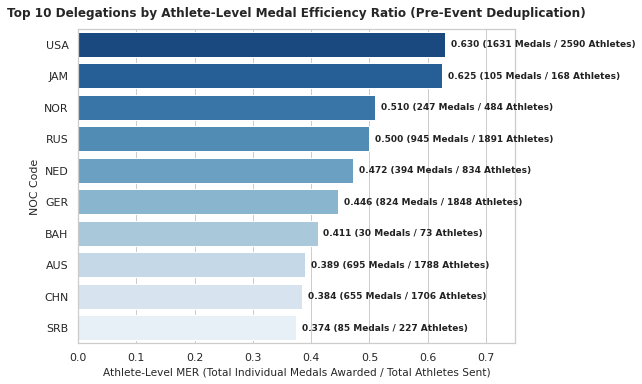

In [8]:
sns.set(style="whitegrid")
plt.rcParams.update({"font.family": "sans-serif", "figure.autolayout": True})

# Complete Top 10 dataset
raw_mer_data = pd.DataFrame(
    {
        "NOC": ["USA", "JAM", "NOR", "RUS", "NED", "GER", "BAH", "AUS", "CHN", "SRB"],
        "Total_Athletes": [2590, 168, 484, 1891, 834, 1848, 73, 1788, 1706, 227],
        "Total_Medals": [1631, 105, 247, 945, 394, 824, 30, 695, 655, 85],
        "Medal_Efficiency_Ratio": [0.630, 0.625, 0.510, 0.500, 0.472, 0.446, 0.411, 0.389, 0.384, 0.374],
    }
)

plt.figure(figsize=(9, 5.5))

ax = sns.barplot(
    data=raw_mer_data,
    x="Medal_Efficiency_Ratio",
    y="NOC",
    palette="Blues_r",
)

ax.set_title(
    "Top 10 Delegations by Athlete-Level Medal Efficiency Ratio (Pre-Event Deduplication)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel(
    "Athlete-Level MER (Total Individual Medals Awarded / Total Athletes Sent)",
    fontsize=10.5,
)
ax.set_ylabel("NOC Code", fontsize=11)
ax.set_xlim(0, 0.75)

# Annotate exact MER values and (Medals / Athletes) counts outside bar ends
for p, (_, row) in zip(ax.patches, raw_mer_data.iterrows()):
    width = p.get_width()
    ax.annotate(
        f"{width:.3f} ({int(row['Total_Medals'])} Medals / {int(row['Total_Athletes'])} Athletes)",
        (width + 0.01, p.get_y() + p.get_height() / 2.0),
        ha="left",
        va="center",
        color="#222222",
        fontweight="bold",
        fontsize=9,
    )

plt.savefig("athlete_level_mer_raw.png", dpi=300, bbox_inches="tight")
plt.show()

Key Finding (Modern Era, 2000–Present):

USA leads overall volume efficiency at 0.630 (1,631 medals across 2,590 athletes).

Jamaica (JAM) emerges as a high-efficiency powerhouse with a 0.625 MER (105 medals across just 168 athletes), demonstrating extraordinary hyper-specialization in sprinting disciplines.

Norway (0.510) and Russia (0.500) follow closely, winning a medal for every two athletes sent.
A Lamusi (Judo): $\text{BMI} = 20.76$, $\Delta\text{BMI} = -4.83$. Identifies a significantly lighter frame compared to the Judo baseline average, pointing toward competing in lower weight classes.A Dijiang (Basketball): $\text{BMI} = 24.69$, $\Delta\text{BMI} = +1.40$. Shows a slightly denser build than the average basketball player, providing trainers with actionable comparative data.